# G1 push recovery — training seed sweep

Compare the pretrained policy with G1 policies fine-tuned using different push strengths. Each training run lasts 200 continuous PPO iterations, also save the strong-push policy after iteration 20 for comparison.

## Setup

Run this installation once on a fresh Colab runtime, then restart the runtime and continue with the imports cell.


In [ ]:

%pip install -q uv

import subprocess
import sys

subprocess.run(
    [
        sys.executable, "-m", "uv", "pip", "install",
        "--system",
        "--python", sys.executable,
        "--reinstall-package", "isaaclab",
        "--reinstall-package", "torch",
        "--reinstall-package", "torchvision",
        "--reinstall-package", "torchaudio",
        "--reinstall-package", "nvidia-cuda-nvrtc",
        "--torch-backend", "cu130",
        "torch==2.11.0+cu130",
        "torchvision==0.26.0+cu130",
        "torchaudio==2.11.0+cu130",
        "wurlitzer>=3.1",
        "isaaclab[video] @ git+https://github.com/isaac-sim/IsaacLab.git@release/3.0.0#subdirectory=tools/wheel_builder",
    ],
    check=True,
)

print("Isaac Lab installation completed. Restart the runtime before proceeding.")


In [ ]:
import ctypes
import site
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import warp as wp

from isaaclab.app import launch_simulation
from isaaclab.envs import ManagerBasedRLEnv
from isaaclab.envs.mdp import push_by_setting_velocity
from isaaclab_rl.rsl_rl import (
    RslRlVecEnvWrapper,
    check_rsl_rl_version,
    create_rsl_rl_runner,
    handle_deprecated_rsl_rl_cfg,
)
from isaaclab_tasks.core.velocity.config.g1.flat_env_cfg import G1FlatEnvCfg
from isaaclab_tasks.core.velocity.config.g1.agents.rsl_rl_ppo_cfg import G1FlatPPORunnerCfg
from isaaclab_tasks.utils.hydra import resolve_presets
from isaaclab_rl.utils.pretrained_checkpoint import (
    get_pretrained_checkpoint_backend_names,
    get_published_pretrained_checkpoint,
)

libraries = [
    p
    for root in site.getsitepackages()
    for p in Path(root).glob("nvidia/**/libnvrtc-builtins.so.13.0")
]
if libraries:
    ctypes.CDLL(str(libraries[0]), mode=ctypes.RTLD_GLOBAL)

wp.config.enable_backward = False

preset_cfg = resolve_presets(G1FlatEnvCfg(), selected=("newton_mjwarp",))
backends = get_pretrained_checkpoint_backend_names(preset_cfg)
pretrained_checkpoint = get_published_pretrained_checkpoint(
    "rsl_rl", "Isaac-Velocity-Flat-G1", *backends
)
print("Pretrained checkpoint:", pretrained_checkpoint)

In [ ]:
training_seeds = list(range(43, 53))
regimes = ["strong", "weak", "default"]
strengths = [0.0, 0.5, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2, 2.5]
trials_per_strength = 100
warmup_steps = 100
recovery_steps = 150
evaluation_seed = 42

output_dir = Path("/content/g1_seed_sweep_uninterrupted")
models_dir = output_dir / "models"
results_dir = output_dir / "results"
models_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)
print("Saving to:", output_dir)

## Training

All three regimes start from the same pretrained G1 and train for 200 uninterrupted PPO iterations. The regimes differ only in their push configuration.

In [ ]:
import shutil

timings_path = output_dir / "training_times.csv"

if timings_path.exists():
    timing_rows = pd.read_csv(timings_path).to_dict("records")
else:
    timing_rows = []

for seed_index, training_seed in enumerate(training_seeds):
    order = regimes[seed_index % len(regimes):] + regimes[:seed_index % len(regimes)]

    for regime in order:
        final_path = models_dir / f"{regime}_seed{training_seed}_200.pt"
        first_path = models_dir / f"{regime}_seed{training_seed}_20.pt"

        if final_path.exists() and first_path.exists():
            print("Already trained:", regime, training_seed)
            continue

        start_time = perf_counter()

        train_cfg = resolve_presets(
            G1FlatEnvCfg(), selected=("newton_mjwarp",)
        )
        train_cfg.scene.num_envs = 512
        train_cfg.seed = training_seed
        train_cfg.sim.visualizer_cfgs = []
        train_cfg.video_recorders = []

        if regime in ("strong", "weak"):
            lateral_strength = 1.6 if regime == "strong" else 0.5
            train_cfg.events.push_robot.interval_range_s = (3.0, 5.0)
            train_cfg.events.push_robot.params["velocity_range"] = {
                "x": (-0.25, 0.25),
                "y": (-lateral_strength, lateral_strength),
            }

        agent_cfg = handle_deprecated_rsl_rl_cfg(
            G1FlatPPORunnerCfg(), check_rsl_rl_version()
        )
        agent_cfg.save_interval = 1_000_000

        log_dir = output_dir / "logs" / f"{regime}_seed{training_seed}"
        log_dir.mkdir(parents=True, exist_ok=True)

        print(f"Training {regime}, seed {training_seed}, 200 iterations")

        with launch_simulation(
            train_cfg,
            {"visualizer": None, "visualizer_explicit": True},
        ):
            env = RslRlVecEnvWrapper(
                ManagerBasedRLEnv(train_cfg),
                clip_actions=agent_cfg.clip_actions,
            )
            try:
                runner = create_rsl_rl_runner(
                    env, agent_cfg, log_dir=str(log_dir)
                )
                runner.load(str(pretrained_checkpoint))

                checkpoint_iteration = runner.current_learning_iteration + 19
                runner.cfg["save_interval"] = checkpoint_iteration

                runner.learn(
                    num_learning_iterations=200,
                    init_at_random_ep_len=True,
                )

                intermediate = log_dir / f"model_{checkpoint_iteration}.pt"
                if not intermediate.exists():
                    raise FileNotFoundError(intermediate)
                shutil.move(str(intermediate), str(first_path))

                last_iteration = runner.current_learning_iteration
                automatic_final = log_dir / f"model_{last_iteration}.pt"
                if automatic_final.exists():
                    shutil.move(str(automatic_final), str(final_path))
                else:
                    runner.save(str(final_path))

            finally:
                env.close()

        elapsed = perf_counter() - start_time
        timing_rows.append({
            "regime": regime,
            "training_seed": training_seed,
            "seconds": elapsed,
            "checkpoint": str(final_path),
        })
        pd.DataFrame(timing_rows).to_csv(timings_path, index=False)
        print(f"Finished {regime}, seed {training_seed}: {elapsed:.1f} seconds")

print("All requested training runs completed")
display(pd.read_csv(timings_path)[["regime", "training_seed", "seconds"]])

## Evaluation

In [ ]:
evaluation_jobs = [
    ("pretrained", -1, pretrained_checkpoint)
]

for training_seed in training_seeds:
    for regime in regimes:
        evaluation_jobs.append((
            regime,
            training_seed,
            models_dir / f"{regime}_seed{training_seed}_200.pt",
        ))
        if regime == "strong":
            evaluation_jobs.append((
                "strong_20",
                training_seed,
                models_dir / f"strong_seed{training_seed}_20.pt",
            ))

num_envs = len(strengths) * trials_per_strength

for regime, training_seed, weights in evaluation_jobs:
    label = "pretrained" if regime == "pretrained" else f"{regime}_seed{training_seed}"
    result_path = results_dir / f"{label}.csv"

    if result_path.exists():
        print("Already evaluated:", label)
        continue

    if not Path(weights).exists():
        raise FileNotFoundError(f"Missing checkpoint: {weights}")

    cfg = resolve_presets(G1FlatEnvCfg(), selected=("newton_mjwarp",))
    cfg.play_mode()
    cfg.scene.num_envs = num_envs
    cfg.seed = evaluation_seed
    cfg.sim.visualizer_cfgs = []
    cfg.video_recorders = []

    cfg.commands.base_velocity.heading_command = False
    cfg.commands.base_velocity.rel_heading_envs = 0.0
    cfg.commands.base_velocity.rel_standing_envs = 0.0
    cfg.commands.base_velocity.ranges.lin_vel_x = (0.8, 0.8)
    cfg.commands.base_velocity.ranges.lin_vel_y = (0.0, 0.0)
    cfg.commands.base_velocity.ranges.ang_vel_z = (0.0, 0.0)
    cfg.events.reset_base.params["pose_range"]["yaw"] = (0.0, 0.0)

    agent_cfg = handle_deprecated_rsl_rl_cfg(
        G1FlatPPORunnerCfg(), check_rsl_rl_version()
    )

    print("Evaluating:", label)
    start_time = perf_counter()

    with launch_simulation(
        cfg, {"visualizer": None, "visualizer_explicit": True}
    ):
        env = RslRlVecEnvWrapper(
            ManagerBasedRLEnv(cfg),
            clip_actions=agent_cfg.clip_actions,
        )
        try:
            runner = create_rsl_rl_runner(env, agent_cfg)
            runner.load(str(weights))
            policy = runner.get_inference_policy(device=env.unwrapped.device)
            obs = env.get_observations()
            device = env.unwrapped.device
            valid = torch.ones(num_envs, dtype=torch.bool, device=device)
            fall_step = torch.full(
                (num_envs,), -1, dtype=torch.long, device=device
            )
            groups = torch.arange(device=device, end=num_envs).reshape(
                len(strengths), trials_per_strength
            )

            with torch.inference_mode():
                for _ in range(warmup_steps):
                    obs, _, dones, _ = env.step(policy(obs))
                    dones = dones.bool()
                    valid &= ~dones
                    policy.reset(dones)

                print("Warmup survivors:", int(valid.sum().item()), "/", num_envs)

                for j, strength in enumerate(strengths):
                    ids = groups[j][valid[groups[j]]]
                    if strength > 0 and ids.numel() > 0:
                        push_by_setting_velocity(
                            env.unwrapped, ids, {"y": (strength, strength)}
                        )

                for step in range(recovery_steps):
                    obs, _, dones, _ = env.step(policy(obs))
                    dones = dones.bool()
                    new_falls = dones & valid & (fall_step < 0)
                    fall_step[new_falls] = step + 1
                    policy.reset(dones)

            rows = []
            for j, strength in enumerate(strengths):
                ids = groups[j]
                tested = int(valid[ids].sum().item())
                fallen = int(
                    ((fall_step[ids] >= 0) & valid[ids]).sum().item()
                )
                rows.append({
                    "regime": regime,
                    "training_seed": training_seed,
                    "evaluation_seed": evaluation_seed,
                    "push_mps": strength,
                    "trials": tested,
                    "falls": fallen,
                    "survived": tested - fallen,
                    "success_rate": (tested - fallen) / tested if tested else np.nan,
                })
        finally:
            env.close()

    pd.DataFrame(rows).to_csv(result_path, index=False)
    print(f"Completed {label} in {perf_counter() - start_time:.1f} seconds")

all_results = pd.concat(
    [pd.read_csv(path) for path in sorted(results_dir.glob("*.csv"))],
    ignore_index=True,
)
all_results.to_csv(output_dir / "all_results.csv", index=False)
print("Results saved:", output_dir / "all_results.csv")

## Results

The shaded region shows a bootstrap 95% confidence interval for the mean across training runs. The thick lines show means.

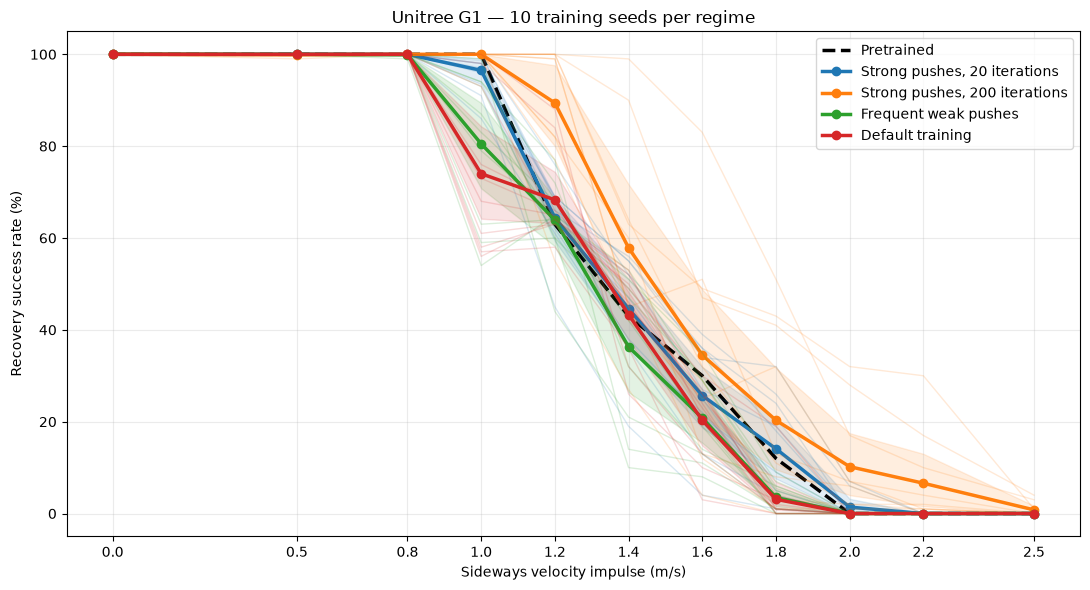

Survival at 2.0 m/s, by training seed (%)


regime,default,strong,strong_20,weak
training_seed,,,,
43,0.0,0.0,0.0,0.0
44,0.0,28.0,1.0,0.0
45,0.0,7.0,0.0,0.0
46,0.0,17.0,0.0,0.0
47,0.0,32.0,6.0,0.0
48,0.0,6.0,0.0,0.0
49,0.0,1.0,0.0,0.0
50,0.0,2.0,7.0,0.0
51,0.0,2.0,0.0,0.0


Training time per policy (seconds)


,regime,training_seed,seconds
0,strong,43,310.948383
1,weak,43,173.667299
2,default,43,172.718642
3,weak,44,174.701424
4,default,44,172.128112
5,strong,44,176.687340
6,default,45,173.566298
7,strong,45,177.685055
8,weak,45,175.206348
9,strong,46,177.244604


In [ ]:
all_results = pd.read_csv(output_dir / "all_results.csv")

fig, ax = plt.subplots(figsize=(11, 6))

baseline = all_results[all_results["regime"] == "pretrained"].sort_values("push_mps")
ax.plot(
    baseline["push_mps"],
    baseline["success_rate"] * 100,
    color="black",
    linestyle="--",
    linewidth=2.5,
    label="Pretrained",
)

for regime, title in [
    ("strong_20", "Strong pushes, 20 iterations"),
    ("strong", "Strong pushes, 200 iterations"),
    ("weak", "Frequent weak pushes"),
    ("default", "Default training"),
]:
    data = all_results[all_results["regime"] == regime]
    wide = data.pivot(index="training_seed", columns="push_mps", values="success_rate")
    wide = wide.reindex(columns=strengths)
    x = np.asarray(strengths, dtype=float)
    values = wide.to_numpy(dtype=float) * 100
    mean = values.mean(axis=0)

    line, = ax.plot(x, mean, marker="o", linewidth=2.5, label=title)
    color = line.get_color()

    for run in values:
        ax.plot(x, run, color=color, alpha=0.17, linewidth=1)

    if len(values) >= 5:
        rng = np.random.default_rng(2026)
        sampled = rng.integers(0, len(values), size=(3000, len(values)))
        bootstrap_means = values[sampled].mean(axis=1)
        lower, upper = np.percentile(bootstrap_means, [2.5, 97.5], axis=0)
    else:
        lower = values.min(axis=0)
        upper = values.max(axis=0)

    ax.fill_between(x, lower, upper, color=color, alpha=0.13)

ax.set_xlabel("Sideways velocity impulse (m/s)")
ax.set_ylabel("Recovery success rate (%)")
ax.set_title(f"Unitree G1 — {len(training_seeds)} training seeds per regime")
ax.set_xticks(strengths)
ax.set_ylim(-5, 105)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / "seed_comparison.png", dpi=200)
plt.show()

rates_2mps = all_results[
    (all_results["push_mps"] == 2.0)
    & (all_results["regime"] != "pretrained")
].pivot(index="training_seed", columns="regime", values="success_rate") * 100

print("Survival at 2.0 m/s, by training seed (%)")
display(rates_2mps.round(1))

print("Training time per policy (seconds)")
display(pd.read_csv(output_dir / "training_times.csv")[[
    "regime", "training_seed", "seconds"
]])

## Backup

In [ ]:
import tarfile
from pathlib import Path
from google.colab import files

archive_path = Path("/content/g1_seed_sweep_uninterrupted_backup.tar.gz")

with tarfile.open(archive_path, "w:gz", compresslevel=1) as archive:
    archive.add(output_dir, arcname="g1_seed_sweep_uninterrupted")
    archive.add(pretrained_checkpoint, arcname="pretrained_g1.pt")

print("Model checkpoints:", len(list(models_dir.glob("*.pt"))))
print("Archive size:", round(archive_path.stat().st_size / 1024**3, 2), "GB")
files.download(str(archive_path))

Model checkpoints: 60
Archive size: 0.11 GB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Restore from a backup

In [ ]:
import tarfile
from pathlib import Path
from google.colab import files

backup_path = Path("/content/g1_seed_sweep_uninterrupted_backup.tar.gz")
if not backup_path.exists():
    files.upload()

with tarfile.open(backup_path, "r:gz") as archive:
    archive.extractall("/content", filter="data")

output_dir = Path("/content/g1_seed_sweep_uninterrupted")
models_dir = output_dir / "models"
results_dir = output_dir / "results"
pretrained_checkpoint = Path("/content/pretrained_g1.pt")

print("Restored checkpoints:", len(list(models_dir.glob("*.pt"))))
print("Restored evaluations:", len(list(results_dir.glob("*.csv"))))

## Videos

In [ ]:
from collections import deque
from pathlib import Path

import imageio.v2 as imageio
import torch
from IPython.display import Video, display

import isaaclab.sim as sim_utils
from isaaclab.app import launch_simulation
from isaaclab.envs import ManagerBasedRLEnv
from isaaclab.envs.mdp import push_by_setting_velocity
from isaaclab.envs.utils.video_recorder_cfg import VideoRecorderCfg
from isaaclab.sensors import CameraCfg
from isaaclab_newton.renderers import NewtonWarpRendererCfg
from isaaclab_tasks.utils.presets import MultiBackendRendererCfg
from isaaclab_tasks.utils.hydra import resolve_presets
from isaaclab_tasks.core.velocity.config.g1.flat_env_cfg import G1FlatEnvCfg
from isaaclab_tasks.core.velocity.config.g1.agents.rsl_rl_ppo_cfg import G1FlatPPORunnerCfg
from isaaclab_rl.rsl_rl import (
    RslRlVecEnvWrapper,
    check_rsl_rl_version,
    create_rsl_rl_runner,
    handle_deprecated_rsl_rl_cfg,
)

video_dir = Path("/content/g1_seed_sweep_uninterrupted/videos")
video_dir.mkdir(parents=True, exist_ok=True)

def record_g1(label, weights, demo_seed=47, push_strength=2.0):
    warmup = 100
    steps = 250

    cfg = resolve_presets(G1FlatEnvCfg(), selected=("newton_mjwarp",))
    cfg.scene.camera = CameraCfg(
        prim_path="{ENV_REGEX_NS}/Camera",
        data_types=["rgb"],
        width=640,
        height=480,
        spawn=sim_utils.PinholeCameraCfg(
            focal_length=24.0,
            horizontal_aperture=20.955,
            clipping_range=(0.1, 100.0),
        ),
        renderer_cfg=MultiBackendRendererCfg(
            newton_renderer=NewtonWarpRendererCfg(enable_shadows=True)
        ),
    )
    cfg = resolve_presets(cfg, selected=("newton_mjwarp", "newton_renderer"))
    cfg.play_mode()
    cfg.scene.num_envs = 1
    cfg.seed = demo_seed
    cfg.sim.visualizer_cfgs = []

    cfg.commands.base_velocity.heading_command = False
    cfg.commands.base_velocity.rel_heading_envs = 0.0
    cfg.commands.base_velocity.rel_standing_envs = 0.0
    cfg.commands.base_velocity.ranges.lin_vel_x = (0.8, 0.8)
    cfg.commands.base_velocity.ranges.lin_vel_y = (0.0, 0.0)
    cfg.commands.base_velocity.ranges.ang_vel_z = (0.0, 0.0)
    cfg.events.reset_base.params["pose_range"]["yaw"] = (0.0, 0.0)

    fps = round(1.0 / (cfg.sim.dt * cfg.decimation))
    prefix = f"{label}_demo{demo_seed}"
    cfg.video_recorders = [
        VideoRecorderCfg(
            source="sensor:camera:rgb",
            output_dir=str(video_dir),
            output_filename_prefix=prefix,
            video_length=steps + 10,
            fps=fps,
        )
    ]

    agent_cfg = handle_deprecated_rsl_rl_cfg(
        G1FlatPPORunnerCfg(), check_rsl_rl_version()
    )
    fell = False

    with launch_simulation(
        cfg, {"visualizer": None, "visualizer_explicit": True}
    ):
        env = RslRlVecEnvWrapper(
            ManagerBasedRLEnv(cfg), clip_actions=agent_cfg.clip_actions
        )
        try:
            runner = create_rsl_rl_runner(env, agent_cfg)
            runner.load(str(weights))
            policy = runner.get_inference_policy(device=env.unwrapped.device)
            obs = env.get_observations()
            camera = env.unwrapped.scene["camera"]
            robot = env.unwrapped.scene["robot"]
            offset = torch.tensor((2.5, -2.5, 1.3), device=env.device)

            with torch.inference_mode():
                for step in range(steps):
                    target = robot.data.root_pos_w.torch.clone()
                    target[:, 2] = 0.8
                    camera.set_world_poses_from_view(
                        eyes=target + offset, targets=target
                    )

                    if step == warmup:
                        push_by_setting_velocity(
                            env.unwrapped,
                            torch.tensor([0], device=env.device),
                            {"x": (0.0, 0.0), "y": (push_strength, push_strength)},
                        )

                    obs, _, dones, _ = env.step(policy(obs))
                    dones = dones.bool()
                    policy.reset(dones)
                    if bool(dones[0].item()):
                        fell = True
                        print(label, "fell at", round((step + 1) / fps, 2), "s")
                        break
        finally:
            env.close()

    clean_path = video_dir / f"{prefix}_clean.mp4"
    recordings = sorted(
        (p for p in video_dir.glob(f"{prefix}*.mp4") if p != clean_path),
        key=lambda p: p.stat().st_mtime_ns,
    )
    if not recordings:
        raise FileNotFoundError(f"No recording found for {label}")

    reader = imageio.get_reader(str(recordings[-1]))
    try:
        with imageio.get_writer(
            str(clean_path), fps=fps, codec="libx264", macro_block_size=16
        ) as writer:
            tail = deque()
            for frame in reader:
                tail.append(frame)
                if len(tail) > (2 if fell else 0):
                    writer.append_data(tail.popleft())
    finally:
        reader.close()

    print(label, "-", "fell" if fell else "survived", "-", clean_path)
    display(Video(str(clean_path), embed=True, width=640))
    return clean_path, fell


In [ ]:
import pandas as pd

all_results = pd.read_csv(output_dir / "all_results.csv")
strong_results = all_results[
    (all_results["regime"] == "strong")
    & (all_results["push_mps"] == 2.0)
]

best_training_seed = int(
    strong_results.sort_values("success_rate", ascending=False)
    .iloc[0]["training_seed"]
)

demo_seed = 47
push_strength = 2.0

print("Strong-policy training seed:", best_training_seed)
print("Demonstration seed:", demo_seed)

original_video, original_fell = record_g1(
    "pretrained", pretrained_checkpoint, demo_seed, push_strength
)
strong_video, strong_fell = record_g1(
    f"strong_seed{best_training_seed}",
    models_dir / f"strong_seed{best_training_seed}_200.pt",
    demo_seed,
    push_strength,
)

print("Original fell:", original_fell)
print("Fine-tuned fell:", strong_fell)


Strong-policy training seed: 47
Demonstration seed: 47
[INFO]: Base environment:
	Environment device    : cuda:0
	Environment seed      : 47
	Physics step-size     : 0.005
	Rendering step-size   : 0.02
	Environment step-size : 0.02


INFO:isaaclab.sensors.camera.camera:Using renderer: NewtonWarpRenderer
  replace_newton_builder_shape_colors(builder, stage)



[INFO]: Time taken for scene creation Last: 1.459151 s, Mean: 0.912259 s, Std: 1.216594 s, N: 72
[INFO]: Scene manager:  <class InteractiveScene>
	Number of environments: 1
	Environment spacing   : 2.5
	Source prim name      : /World/envs/env_0
	Global prim paths     : ['/World/ground']
	Replicate physics     : True
Finalize builder took: Last: 0.628476 s, Mean: 0.247199 s, Std: 0.222509 s, N: 72
Contact sensor construction took: Last: 0.001493 s, Mean: 0.042713 s, Std: 0.047299 s, N: 72


Initialize solver took: Last: 0.288972 s, Mean: 0.799350 s, Std: 3.282662 s, N: 72
[INFO]: Time taken for simulation start Last: 2.551245 s, Mean: 1.455228 s, Std: 5.190526 s, N: 72
[INFO] Command Manager:  <CommandManager> contains 1 active terms.
+------------------------------------------------+
|              Active Command Terms              |
+-------+---------------+------------------------+
| Index | Name          |          Type          |
+-------+---------------+------------------------+
|   0   | base_velocity | UniformVelocityCommand |
+-------+---------------+------------------------+

[INFO] Event Manager:  <EventManager> contains 2 active terms.
+---------------------------------------+
| Active Event Terms in Mode: 'startup' |
+----------+----------------------------+
|  Index   | Name                       |
+----------+----------------------------+
|    0     | physics_material           |
|    1     | add_base_mass              |
+----------+------------------------

[INFO]: Base environment:
	Environment device    : cuda:0
	Environment seed      : 47
	Physics step-size     : 0.005
	Rendering step-size   : 0.02
	Environment step-size : 0.02


INFO:isaaclab.sensors.camera.camera:Using renderer: NewtonWarpRenderer


[INFO]: Time taken for scene creation Last: 1.360466 s, Mean: 0.918399 s, Std: 1.209254 s, N: 73
[INFO]: Scene manager:  <class InteractiveScene>
	Number of environments: 1
	Environment spacing   : 2.5
	Source prim name      : /World/envs/env_0
	Global prim paths     : ['/World/ground']
	Replicate physics     : True
Finalize builder took: Last: 0.617756 s, Mean: 0.252275 s, Std: 0.225175 s, N: 73
Contact sensor construction took: Last: 0.000850 s, Mean: 0.042139 s, Std: 0.047224 s, N: 73


Initialize solver took: Last: 0.338665 s, Mean: 0.793040 s, Std: 3.260232 s, N: 73
[INFO]: Time taken for simulation start Last: 1.003282 s, Mean: 1.449037 s, Std: 5.154626 s, N: 73
[INFO] Command Manager:  <CommandManager> contains 1 active terms.
+------------------------------------------------+
|              Active Command Terms              |
+-------+---------------+------------------------+
| Index | Name          |          Type          |
+-------+---------------+------------------------+
|   0   | base_velocity | UniformVelocityCommand |
+-------+---------------+------------------------+

[INFO] Event Manager:  <EventManager> contains 2 active terms.
+---------------------------------------+
| Active Event Terms in Mode: 'startup' |
+----------+----------------------------+
|  Index   | Name                       |
+----------+----------------------------+
|    0     | physics_material           |
|    1     | add_base_mass              |
+----------+------------------------

Original fell: True
Fine-tuned fell: False
